In [7]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from src.data import load_data, time_split, FEATURES
from src.metrices import (evaluate, precision_at_k, recall_at_k,
                          dollars_caught_at_k, bootstrap_ci)

df = load_data()
train, val, test = time_split(df)
X_test, y_test = test[FEATURES], test["Class"]
print("test rows:", len(test), "| frauds in test:", y_test.sum())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
test rows: 56962 | frauds in test: 75


In [ ]:
trainval = pd.concat([train, val])
X_tv, y_tv = trainval[FEATURES], trainval["Class"]
pos, neg = y_tv.sum(), (y_tv == 0).sum()

xgbc = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(neg / pos) ** 0.5,
    eval_metric="aucpr", tree_method="hist",
    random_state=42, n_jobs=-1,
)
xgbc.fit(X_tv, y_tv)
scores = xgbc.predict_proba(X_test)[:, 1]      # fraud score for every test row

In [ ]:
res = evaluate(y_test, scores)
pd.DataFrame({"XGBoost (test)": res}).T.round(3)

,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
XGBoost (test),0.807,0.982,0.733,0.222,0.84,0.114,0.867


In [ ]:
y = y_test.values
n, total_fraud = len(y), y.sum()

rows = []
for b in [0.001, 0.0025, 0.005, 0.01, 0.02]:
    k = int(n * b)
    caught = int(y[np.argsort(-scores)[:k]].sum())
    rows.append({"budget": f"{b:.2%}", "transactions reviewed": k,
                 "frauds caught": caught, "false alarms": k - caught,
                 "precision": round(caught / k, 3),
                 "recall": round(caught / total_fraud, 3),
                 "max possible precision": round(min(1, total_fraud / k), 3)})
pd.DataFrame(rows)

,budget,transactions reviewed,frauds caught,false alarms,precision,recall,max possible precision
0,0.10%,56,55,1,0.982,0.733,1.000
1,0.25%,142,62,80,0.437,0.827,0.528
2,0.50%,284,63,221,0.222,0.840,0.264
3,1.00%,569,65,504,0.114,0.867,0.132
4,2.00%,1139,67,1072,0.059,0.893,0.066


In [8]:
k = int(n * 0.005)
p_lo, p_hi = bootstrap_ci(y, scores, precision_at_k, k=k)
r_lo, r_hi = bootstrap_ci(y, scores, recall_at_k, k=k)
dollars = dollars_caught_at_k(y, scores, test["Amount"].values, k)

print(f"Precision@0.5%: {precision_at_k(y, scores, k):.3f}  (95% CI {p_lo:.3f} to {p_hi:.3f})")
print(f"Recall@0.5%   : {recall_at_k(y, scores, k):.3f}  (95% CI {r_lo:.3f} to {r_hi:.3f})")
print(f"Share of fraud DOLLARS caught at 0.5% budget: {dollars:.1%}")
print(f"Random review would catch about: {0.005:.1%} of fraud")

Precision@0.5%: 0.222  (95% CI 0.167 to 0.275)
Recall@0.5%   : 0.840  (95% CI 0.750 to 0.915)
Share of fraud DOLLARS caught at 0.5% budget: 77.6%
Random review would catch about: 0.5% of fraud


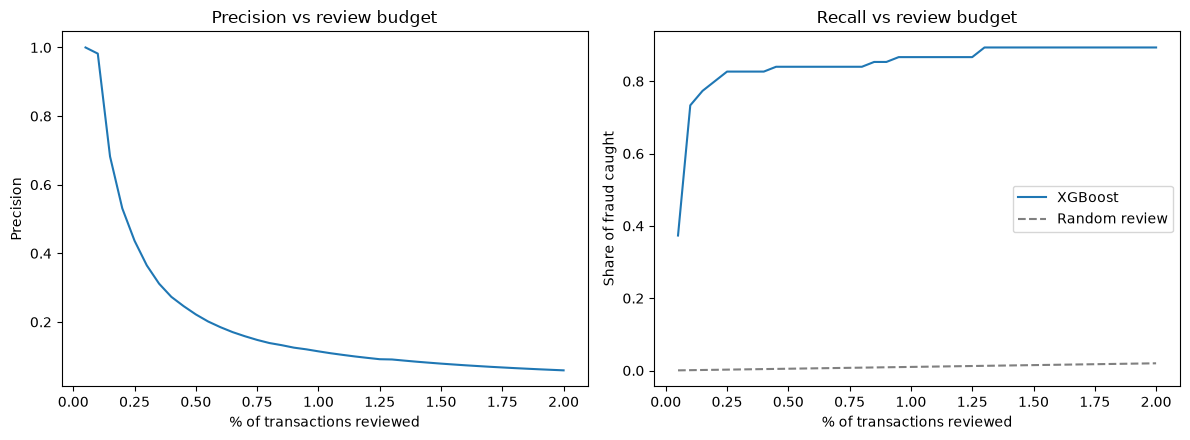

In [9]:
budgets = np.linspace(0.0005, 0.02, 40)
order = np.argsort(-scores)
hits = np.cumsum(y[order])
ks = np.maximum((budgets * n).astype(int), 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(budgets * 100, hits[ks - 1] / ks)
ax[0].set(title="Precision vs review budget", xlabel="% of transactions reviewed", ylabel="Precision")
ax[1].plot(budgets * 100, hits[ks - 1] / total_fraud, label="XGBoost")
ax[1].plot(budgets * 100, budgets, "--", color="gray", label="Random review")
ax[1].set(title="Recall vs review budget", xlabel="% of transactions reviewed", ylabel="Share of fraud caught")
ax[1].legend()
plt.tight_layout()
plt.savefig("../reports/xgb_budget_curves.png", dpi=150)
plt.show()

In [12]:
k = int(n * 0.005)
top = set(np.argsort(-scores)[:k])
fraud_idx = np.where(y == 1)[0]

test_r = test.reset_index(drop=True).copy()
test_r["score"] = scores
test_r["rank"] = (-scores).argsort().argsort() + 1        # 1 = most suspicious
f = test_r.loc[fraud_idx].copy()
f["status"] = np.where(f.index.isin(top), "caught", "missed")

print(f["status"].value_counts())
print(f.groupby("status")["Amount"].describe().round(2))
f[f["status"] == "missed"][["Amount", "score", "rank"]].sort_values("rank").head(10)


status
caught    63
missed    12
Name: count, dtype: int64
        count    mean     std  min   25%   50%    75%      max
status                                                        
caught   63.0   95.17  245.08  0.0  0.77  2.22  54.55  1504.93
missed   12.0  144.48  318.86  0.0  2.97  7.80  78.68  1096.99


,Amount,score,rank
17711,357.95,0.002274,464
24046,7.06,0.001963,537
4133,8.00,0.001452,715
24036,3.14,0.001434,722
26499,187.11,0.000638,1546
46537,0.00,0.000240,3533
21394,1096.99,0.000195,4127
17502,2.47,0.000185,4284
26550,7.59,0.000173,4517
35235,1.00,0.000117,6286


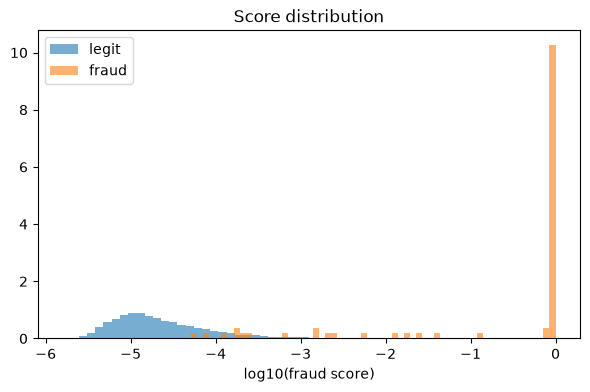

In [13]:
plt.figure(figsize=(7, 4))
plt.hist(np.log10(test_r[test_r.Class == 0]["score"] + 1e-6), bins=60, alpha=.6, density=True, label="legit")
plt.hist(np.log10(test_r[test_r.Class == 1]["score"] + 1e-6), bins=60, alpha=.6, density=True, label="fraud")
plt.xlabel("log10(fraud score)"); plt.legend(); plt.title("Score distribution")
plt.show()

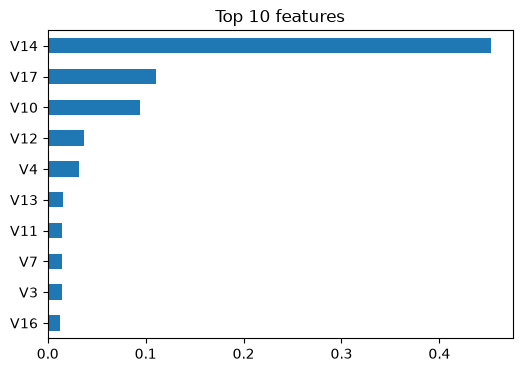

In [14]:
imp = pd.Series(xgbc.feature_importances_, index=FEATURES).sort_values().tail(10)
imp.plot(kind="barh", figsize=(6, 4)); plt.title("Top 10 features"); plt.show()

In [15]:
import os
os.makedirs("../reports", exist_ok=True)
pd.DataFrame(rows).to_csv("../reports/xgb_test_budget_table.csv", index=False)
np.savez("../reports/xgb_test_scores.npz", y=y, scores=scores, amount=test["Amount"].values)